# 종합 튜닝과 실험 로그

**이 노트북에서 할 일**

1. 06절 가중치와 10절 관련성 비중을 곱해 설정 서른여섯 벌을 만듭니다.
2. 개발 열다섯 문항으로 서른여섯 벌을 재고 기록 파일에 남깁니다.
3. 기록을 보고 설정 한 벌을 고른 뒤 시험 열다섯 문항에 한 번만 적용합니다.
4. 고른 설정으로 찾은 글을 모델에 넣어 답을 쓰고 마지막 기록을 남깁니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 청크 1번과 질문 30번으로 모두 서른한 번입니다.
답을 쓰는 모델 요청은 통합 실행 한 번뿐입니다.
예상 비용은 미화 0.01달러 아래이고 실행 시간은 2분 안팎입니다.

**쓰는 파일** — 이 절은 이 챕터에서 처음으로 파일을 씁니다.
실습 폴더 `runs/` 아래에 기록 파일 세 개와 같은 내용의 사본 세 개를 만듭니다.
사본 폴더 이름에는 실행한 시각이 들어가므로 실행할 때마다 새로 생깁니다.

**데이터** — 세 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)
- Ch 11 원본 질문 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`(30줄)

**강의와 실습 범위** — 강의 시간에는 5~10절을 읽습니다.
지표와 기록 한 줄을 만드는 자리가 5절이고 설정 서른여섯 벌이 6절입니다.
7절이 개발 결과 읽기, 8절이 설정 고르기, 9절이 시험 한 번입니다.
1~4절은 함께 실행하고 10절은 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 다섯 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

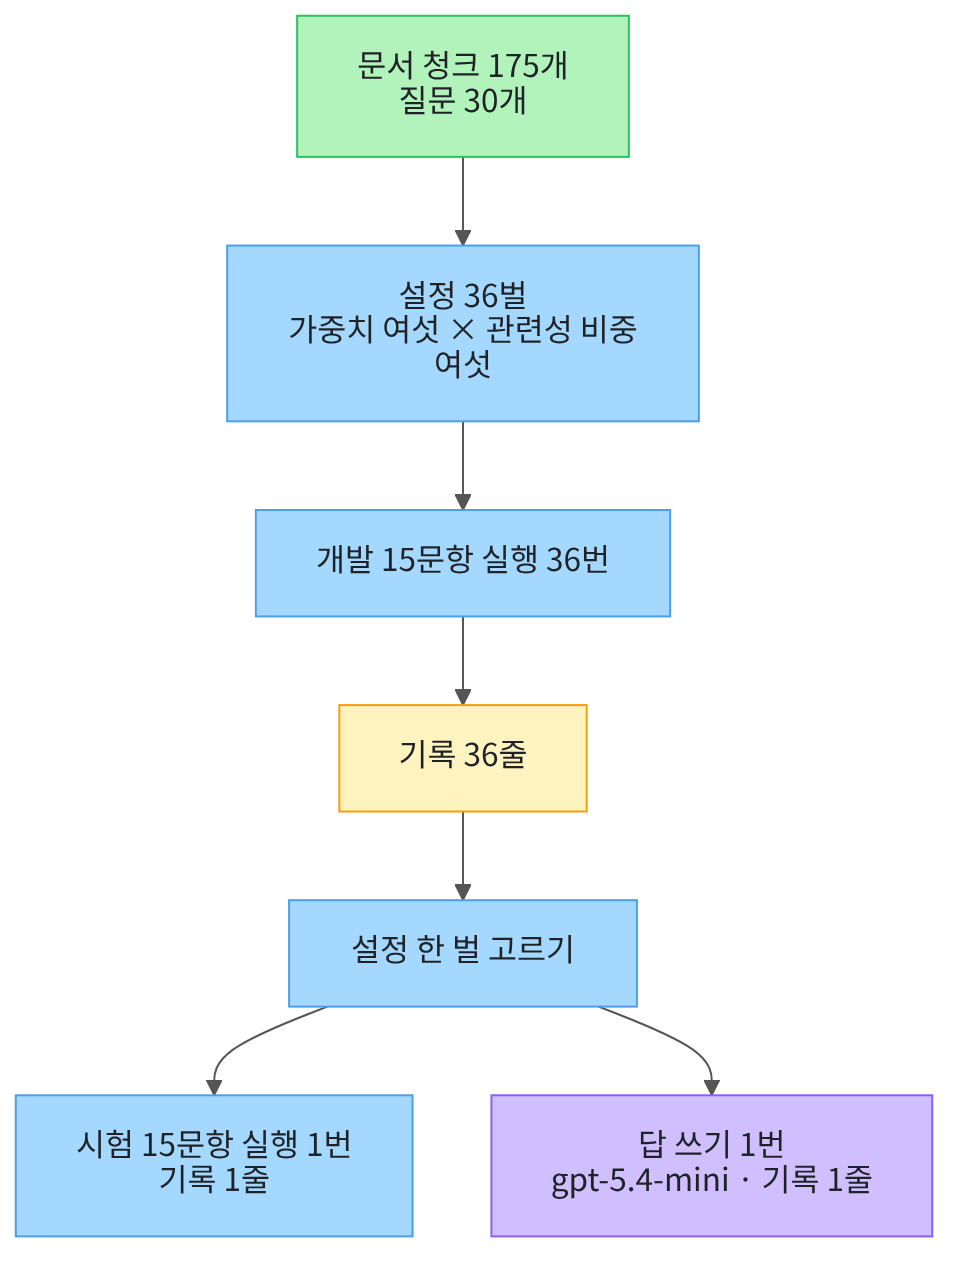

맨 위 초록 상자가 07~11절과 같은 자료입니다.
그 아래 파란 상자에서 손잡이 두 개를 곱해 설정 서른여섯 벌을 만듭니다.
개발 열다섯 문항으로 서른여섯 번 재고 노란 상자에 기록 서른여섯 줄을 남깁니다.
그 기록을 보고 설정 한 벌을 고른 뒤에야 시험 열다섯 문항을 한 번 엽니다.
맨 아래 오른쪽 보라 상자가 이 절에서 답을 쓰는 모델을 부르는 한 자리입니다.

## 1. 준비

첫 셀은 패키지 다섯 개를 설치하고 설치된 버전을 출력합니다.
11절과 같은 다섯 개입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0


langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `langchain: 1.4.0`과 `rank-bm25: 0.2.2`가 보입니다.
다섯 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 아홉 개를 불러옵니다.

In [2]:
# 자료 읽기·제곱근·지문 만들기·폴더 만들기·시간 적기와 검색 도구를 불러옵니다
import hashlib
import json
import math
import os
import time

from kiwipiepy import Kiwi
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi

print("불러온 이름:", "hashlib", "json", "math", "os", "time", "Kiwi", "init_chat_model", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: hashlib json math os time Kiwi init_chat_model OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 아홉 개가 붙은 한 줄입니다.
이름 `hashlib`과 `time`이 07~11절에는 없던 것입니다.
지문을 만들 때 `hashlib`을 쓰고 실행 이름에 시각을 적을 때 `time`을 씁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 문장을 고르게 합니다.
설정 `reasoning_effort="none"`은 답을 쓰기 전에 따로 생각하는 단계를 두지 않게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-18에 이 모델로 실행한 결과입니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~11절과 같은 코드입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. 확인 줄도 통과했습니다.

다음 셀은 07~11절과 같은 자료 두 벌을 읽습니다.

In [6]:
# 07~11절과 같은 파일 두 벌을 읽습니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07~11절과 같은 파일이라 세 값도 같습니다.

## 2. 입력 지문과 값 정하기

기록에는 어떤 입력으로 잰 값인지도 함께 남깁니다.
파일 내용이 한 글자만 달라져도 값이 달라지는 짧은 글을 지문이라고 부릅니다.
다음 셀은 지문을 만드는 함수와 글을 파일로 쓰는 함수를 정의합니다.

In [7]:
# 파일 하나의 지문을 만드는 함수와 글을 파일로 쓰는 함수입니다(Ch 11 01절·Ch 2 05절 코드)
def file_fingerprint(path):
    with open(path, "rb") as file:
        file_bytes = file.read()
    return hashlib.sha256(file_bytes).hexdigest()


def write_text(path, text_value):
    with open(path, "w", encoding="utf-8") as file:
        file.write(text_value)

정의 셀이라 출력이 없습니다.
첫 함수는 파일을 바이트로 읽어 SHA-256 지문을 냅니다. Ch 11 01절과 같은 코드입니다.
둘째 함수는 글 하나를 파일로 씁니다. Ch 2 05절에서 배운 모양입니다.

다음 셀은 Ch 11 원본 질문 파일과 이 챕터 복제본이 같은지 보고 지문 두 개를 만듭니다.

In [8]:
# Ch 11 원본 질문 파일과 이 챕터 복제본이 같은지 보고 두 입력의 지문을 만듭니다
query_source = "labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
with open(root_path + "/" + query_source, encoding="utf-8") as file:
    source_lines = file.read().splitlines()
source_queries = []
for line in source_lines:
    source_queries.append(json.loads(line))
corpus_fingerprint = file_fingerprint(data_path + "/advanced-documents.json")
query_fingerprint = file_fingerprint(root_path + "/" + query_source)
print("Ch 11 원본 질문 줄 수:", len(source_queries))
print("이 챕터 복제본과 같은가:", source_queries == queries)
print("문서 지문 앞 열 글자:", corpus_fingerprint[:10])
assert source_queries == queries, "Ch 11 원본 질문과 이 챕터 복제본이 다릅니다."

Ch 11 원본 질문 줄 수: 30
이 챕터 복제본과 같은가: True
문서 지문 앞 열 글자: 832d89c28a


**결과 읽기** — `Ch 11 원본 질문 줄 수: 30`과 `이 챕터 복제본과 같은가: True`가 보입니다.
줄 `문서 지문 앞 열 글자:` 뒤의 값은 문서 파일의 지문입니다.
지문은 실행마다 같지만 파일을 고치면 달라지므로 본문에 인용하지 않습니다.

다음 셀은 01~11절에서 쓴 값을 그대로 다시 정합니다.

In [9]:
# 01~11절에서 쓴 값을 그대로 다시 정합니다
similarity_top = 1
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
candidate_count = 8
recall_place = 3
report_place = 5
print("코사인 유사도의 가장 큰 값:", similarity_top, "| 남길 품사 표시 수:", len(keep_tags))
print("순위 상수:", rank_constant, "| 후보 수:", candidate_count)
print("부모 문서 재현율을 재는 자리:", recall_place, "| 보고 자리:", report_place)

코사인 유사도의 가장 큰 값: 1 | 남길 품사 표시 수: 9
순위 상수: 60 | 후보 수: 8
부모 문서 재현율을 재는 자리: 3 | 보고 자리: 5


**결과 읽기** — 줄 `순위 상수: 60 | 후보 수: 8`은 06~11절과 같은 값입니다.
줄 `부모 문서 재현율을 재는 자리: 3 | 보고 자리: 5`도 08~11절과 같습니다.

다음 셀은 이 절에서 바꿔 볼 손잡이 두 가지를 정합니다.
가중치는 06절에서 순위 두 개를 합칠 때 준 몫이고 여섯 가지를 봅니다.
관련성 비중은 10절에서 다양성과 관련성을 맞바꾸던 값이고 여섯 가지를 봅니다.

In [10]:
# 이 절에서 바꿔 볼 손잡이 두 가지와 기록에 남길 지표 칸 이름을 정합니다
weight_choices = [[1.0, 0.0], [3.0, 1.0], [2.0, 1.0], [1.0, 1.0], [1.0, 2.0], [0.0, 1.0]]
relevance_choices = [1.0, 0.8, 0.6, 0.4, 0.2, 0.0]
metric_names = ["recall_at_3", "recall_at_5", "recall_at_50", "precision_at_5", "ndcg_at_5", "chunk_precision_at_5"]
select_name = "chunk_precision_at_5"
print("가중치 여섯 가지:", weight_choices)
print("관련성 비중 여섯 가지:", relevance_choices)
print("만들 설정 수:", len(weight_choices) * len(relevance_choices))
print("기록에 남길 지표 칸 수:", len(metric_names))
print("설정을 고를 칸:", select_name)

가중치 여섯 가지: [[1.0, 0.0], [3.0, 1.0], [2.0, 1.0], [1.0, 1.0], [1.0, 2.0], [0.0, 1.0]]
관련성 비중 여섯 가지: [1.0, 0.8, 0.6, 0.4, 0.2, 0.0]
만들 설정 수: 36
기록에 남길 지표 칸 수: 6
설정을 고를 칸: chunk_precision_at_5


**결과 읽기** — 줄 `만들 설정 수: 36`이 여섯 곱하기 여섯입니다.
줄 `기록에 남길 지표 칸 수: 6` 가운데 넷은 Ch 11 도구가 쓰는 칸 이름입니다.
줄 `설정을 고를 칸: chunk_precision_at_5`가 08~11절에서 쓰던 문서 청크 정밀도입니다.
왜 이 칸으로 고르는지는 7절에서 출력을 보고 정합니다.

## 3. 검색에 쓸 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.

In [11]:
# 문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다(07~11절과 같은 코드)
chunk_texts = []
chunk_ids = []
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름 앞머리가 그 문서 청크의 부모 문서 ID입니다.

기록에는 문서 ID와 쪽 번호도 함께 남깁니다.
다음 셀은 문서 청크 ID로 부모·쪽·본문을 바로 찾을 수 있게 짝을 만듭니다.

In [12]:
# 문서 청크 ID로 부모 문서 ID와 쪽 번호와 본문을 바로 찾게 짝을 만듭니다
parent_by_chunk = {}
page_by_chunk = {}
text_by_chunk = {}
for i in range(len(chunks)):
    chunk_id = chunk_ids[i]
    parent_by_chunk[chunk_id] = chunks[i]["parent_id"]
    page_by_chunk[chunk_id] = chunks[i]["page"]
    text_by_chunk[chunk_id] = chunk_texts[i]
print("짝지은 문서 청크 수:", len(parent_by_chunk))
print("첫 문서 청크의 부모 문서 ID:", parent_by_chunk[chunk_ids[0]])
print("첫 문서 청크의 쪽 번호:", page_by_chunk[chunk_ids[0]])

짝지은 문서 청크 수: 175
첫 문서 청크의 부모 문서 ID: E01
첫 문서 청크의 쪽 번호: 1


**결과 읽기** — `짝지은 문서 청크 수: 175`가 보입니다.
줄 `첫 문서 청크의 부모 문서 ID: E01`과 `첫 문서 청크의 쪽 번호: 1`이 기록에 들어갈 값입니다.

다음 셀은 문서 청크를 벡터로 바꿉니다. 01~11절과 같은 모델을 씁니다.

In [13]:
# 01~11절과 같은 모델로 문서 청크를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
vector_by_chunk = {}
for i in range(len(chunk_ids)):
    vector_by_chunk[chunk_ids[i]] = chunk_vectors[i]
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
여기까지 임베딩 요청은 한 번입니다.

## 4. 앞 절에서 만든 함수 다시 만들기

다음 열여섯 셀은 01~11절에서 만든 함수 스물네 개를 같은 코드로 다시 정의합니다.
셀마다 첫 줄 주석에 어느 절 함수인지 적었습니다.
앞 절에서 이미 읽은 코드라 셀 하나에 함수를 둘이나 셋씩 담았습니다.
모두 정의 셀이라 출력이 없습니다.

In [14]:
# 답할 수 있고 정답 부모 문서 ID가 있는 질문만 남깁니다(08~11절과 같은 코드)
def eligible_items(subset):
    picked = []
    for item in subset:
        gold_ids = []
        # 같은 정답 ID가 두 번 적혀 있으면 지표의 나누는 수가 달라져 한 번만 둡니다
        for gold_id in item["gold_doc_ids"]:
            if gold_id not in gold_ids:
                gold_ids.append(gold_id)
        item["gold_doc_ids"] = gold_ids
        if item["answerable"] and len(gold_ids) > 0:
            picked.append(item)
    return picked

In [15]:
# 01절 점곱·길이·코사인 유사도 함수를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

In [16]:
# 01절 코사인 거리와 04~11절 형태소 고르기를 같은 코드로 다시 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity


kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

In [17]:
# 05~11절과 같은 코드로 거리가 작은 순서의 순위 목록을 만듭니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [18]:
# 05~11절과 같은 코드로 낱말 겹침 점수가 큰 순서의 순위 목록을 만듭니다
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

In [19]:
# 07~11절 문서 청크 ID 모으기와 부모 문서 ID로 바꾸기를 같은 코드로 다시 정의합니다
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids


def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        # 여러 문서 청크가 같은 부모를 가리키면 처음 나온 자리만 남깁니다
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

In [20]:
# 06~11절과 같은 코드로 순위 목록 여러 개의 자리 몫을 더합니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

In [21]:
# 06~11절과 같은 코드로 합친 점수가 큰 순서의 문서 청크 ID 목록을 만듭니다
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

In [22]:
# Ch 11 02절 재현율을 같은 코드로 다시 정의합니다
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

In [23]:
# Ch 11 03절 정밀도와 08~11절 문서 청크 정밀도를 같은 코드로 다시 정의합니다
def precision_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / cutoff


def chunk_precision_at(found_chunk_ids, gold_doc_ids, cutoff):
    top_ids = found_chunk_ids[:cutoff]
    found_count = 0
    for chunk_id in top_ids:
        if parent_by_chunk[chunk_id] in gold_doc_ids:
            found_count = found_count + 1
    return found_count / cutoff

In [24]:
# Ch 11 04절 자리 무게와 자리 무게 합을 같은 코드로 다시 정의합니다
def rank_weight(position):
    return 1 / math.log2(position + 2)


def dcg_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    total = 0.0
    for position in range(len(top_ids)):
        if top_ids[position] in gold_doc_ids:
            total = total + rank_weight(position)
    return total

In [25]:
# Ch 11 04절 가장 좋은 무게 합과 0에서 1로 맞춘 값을 같은 코드로 다시 정의합니다
def ideal_dcg(gold_doc_ids, cutoff):
    gold_count = len(gold_doc_ids)
    if gold_count > cutoff:
        gold_count = cutoff
    total = 0.0
    for position in range(gold_count):
        total = total + rank_weight(position)
    return total


def ndcg_at(doc_ids, gold_doc_ids, cutoff):
    best_total = ideal_dcg(gold_doc_ids, cutoff)
    return dcg_at(doc_ids, gold_doc_ids, cutoff) / best_total

In [26]:
# 10절 닮은 정도와 MMR 점수를 같은 코드로 다시 정의합니다
def similarity_to_chosen(candidate_vectors, chosen, index):
    biggest = 0.0
    for chosen_index in chosen:
        similarity = cosine_similarity(candidate_vectors[index], candidate_vectors[chosen_index])
        if similarity > biggest:
            biggest = similarity
    return biggest


def mmr_score(question_vector, candidate_vectors, chosen, index, relevance_weight):
    # 두 비중을 더하면 1이 되므로 나머지 비중은 빼서 만듭니다
    diversity_weight = similarity_top - relevance_weight
    relevance = cosine_similarity(question_vector, candidate_vectors[index])
    biggest = similarity_to_chosen(candidate_vectors, chosen, index)
    return relevance_weight * relevance - diversity_weight * biggest

In [27]:
# 10절 「아직 고르지 않은 후보 가운데 점수가 가장 큰 자리 찾기」를 같은 코드로 다시 정의합니다
def best_candidate(question_vector, candidate_vectors, chosen, relevance_weight):
    best_index = -1
    best_value = 0.0
    for index in range(len(candidate_vectors)):
        # 이미 고른 자리는 건너뜁니다
        if index not in chosen:
            value = mmr_score(question_vector, candidate_vectors, chosen, index, relevance_weight)
            if best_index == -1 or value > best_value:
                best_index = index
                best_value = value
    return best_index

In [28]:
# 10절 MMR 고르기를 같은 코드로 다시 정의합니다
def mmr(question_vector, candidate_vectors, pick_count, relevance_weight):
    chosen = []
    limit = pick_count
    # 후보보다 많이 고를 수는 없습니다
    if len(candidate_vectors) < pick_count:
        limit = len(candidate_vectors)
    while len(chosen) < limit:
        chosen.append(best_candidate(question_vector, candidate_vectors, chosen, relevance_weight))
    return chosen

In [29]:
# 10절 「후보 목록에서 문서 청크를 고르는 겉면」을 같은 코드로 다시 정의합니다
def mmr_pick(question_vector, found_chunk_ids, place, relevance_weight):
    found_vectors = []
    for chunk_id in found_chunk_ids:
        found_vectors.append(vector_by_chunk[chunk_id])
    chosen = mmr(question_vector, found_vectors, place, relevance_weight)
    picked = []
    for index in chosen:
        picked.append(found_chunk_ids[index])
    return picked

여기까지가 다시 만든 함수입니다. 세 가지만 짚고 넘어갑니다.

Ch 11 04절 자리 무게는 01~11절에서 쓰지 않았고 이 절에서 처음 다시 씁니다.
기록 파일의 칸 이름이 Ch 11 도구 이름이라 그 계산을 그대로 써야 하기 때문입니다.
정밀도는 이름이 둘입니다. 부모 문서를 세는 쪽이 Ch 11 03절 판이고 문서 청크를 세는 쪽이 08절 판입니다.

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [30]:
# 문서 청크마다 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04~11절과 같은 코드)
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07~11절과 같은 값입니다.

다음 셀은 개발 묶음을 가릅니다.
Ch 11이 정한 약속은 개발 15문항으로 설정을 고르는 것입니다.
시험 15문항은 설정을 다 고른 뒤 9절에서 한 번만 엽니다.

In [31]:
# 질문 30개에서 개발 묶음만 고르고 질문 ID로 찾을 수 있게 짝지어 둡니다
dev_all = []
for query in queries:
    if query["split"] == "dev":
        dev_all.append(query)
dev_queries = eligible_items(dev_all)
question_count = len(dev_queries)
item_by_qid = {}
for item in dev_queries:
    item_by_qid[item["qid"]] = item
print("개발 질문 수:", question_count)
print("시험 질문 수:", len(queries) - len(dev_all))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.

다음 셀은 질문 하나를 후보 목록으로 바꾸는 함수 둘입니다. 11절과 같은 얼개입니다.

In [32]:
# 질문 하나로 순위 목록 두 개를 만들고 설정대로 앞자리를 후보로 자릅니다
def question_lists(question_vector, question):
    distance_hits = rank_by_distance(question_vector, all_chunk_count)
    score_hits = rank_by_bm25(question, all_chunk_count)
    return [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]


def candidates_of(question_id, config):
    fused_ids = fuse_rank(lists_by_qid[question_id], config["weights"])
    return fused_ids[:config["candidate_k"]]

정의 셀이라 출력이 없습니다.
첫 함수는 벡터 거리 순위와 낱말 겹침 순위 두 개를 목록에 담아 냅니다.
둘째 함수는 그 두 목록을 설정의 가중치로 합쳐 앞자리 여덟 개를 자릅니다.
11절과 다른 점은 가중치를 설정에서 꺼내 쓴다는 것뿐입니다.

다음 셀은 개발 질문마다 벡터와 순위 목록을 미리 만들어 둡니다.
설정이 바뀌어도 이 두 가지는 그대로라 한 번만 만들면 됩니다.

In [33]:
# 개발 질문 열다섯 개를 벡터로 바꾸고 순위 목록 두 개씩 미리 만듭니다(임베딩 요청 15번)
vector_by_qid = {}
lists_by_qid = {}
for item in dev_queries:
    question_vector = embedding_model.embed_query(item["question"])
    vector_by_qid[item["qid"]] = question_vector
    lists_by_qid[item["qid"]] = question_lists(question_vector, item["question"])
first_id = dev_queries[0]["qid"]
print("질문 벡터 수:", len(vector_by_qid))
print("질문 하나의 순위 목록 수:", len(lists_by_qid[first_id]))
print("순위 목록 하나의 문서 청크 수:", len(lists_by_qid[first_id][0]))

질문 벡터 수: 15
질문 하나의 순위 목록 수: 2
순위 목록 하나의 문서 청크 수: 175


**결과 읽기** — `질문 벡터 수: 15`와 `질문 하나의 순위 목록 수: 2`가 보입니다.
줄 `순위 목록 하나의 문서 청크 수: 175`는 문서 청크를 모두 줄 세웠다는 뜻입니다.
여기까지 임베딩 요청은 열여섯 번입니다.

## 5. 지표와 기록 한 줄 만들기

기록에 남길 값은 여섯 개입니다. 앞의 네 개는 Ch 11 도구가 쓰는 칸 이름입니다.
다음 셀은 값 여섯 개를 내는 함수와 보고 자리를 기록 모양으로 바꾸는 함수입니다.

In [34]:
# 보고한 부모 문서와 문서 청크에서 기록에 남길 값 여섯 개를 냅니다
def metrics(candidate_doc_ids, top_doc_ids, gold_doc_ids, picked_chunk_ids):
    narrow = recall_at(top_doc_ids, gold_doc_ids, recall_place)
    wide = recall_at(top_doc_ids, gold_doc_ids, report_place)
    inside = recall_at(candidate_doc_ids, gold_doc_ids, candidate_count)
    doc_precision = precision_at(top_doc_ids, gold_doc_ids, report_place)
    gain = ndcg_at(top_doc_ids, gold_doc_ids, report_place)
    chunk_precision = chunk_precision_at(picked_chunk_ids, gold_doc_ids, report_place)
    return narrow, wide, inside, doc_precision, gain, chunk_precision


# 고른 문서 청크를 기록 모양(문서 ID·쪽·청크 ID·자리)으로 바꿉니다
def top_results_of(picked_chunk_ids):
    hits = []
    for chunk_id in picked_chunk_ids:
        hit = {"doc_id": parent_by_chunk[chunk_id], "page": page_by_chunk[chunk_id], "chunk_id": chunk_id}
        hit["rank"] = len(hits) + 1
        hits.append(hit)
    return hits

정의 셀이라 출력이 없습니다.
칸 `recall_at_3`과 `recall_at_5`는 보고한 부모 문서 차례에서 자리만 다르게 잰 재현율입니다.
칸 `recall_at_50`은 후보 여덟 개의 부모 문서에서 잰 재현율입니다.
이름에 50이 붙은 것은 Ch 11 도구가 정한 이름이라 그대로 두었기 때문입니다.
이름을 바꾸면 과정 검사 스크립트가 이 칸을 찾지 못해 멈춥니다.

칸 `precision_at_5`는 부모 문서를 세고 `chunk_precision_at_5`는 문서 청크를 셉니다.
둘 다 나누는 수는 보고 자리 5로 고정입니다. Ch 11 03절에서 배운 고정 분모입니다.
둘째 함수는 고른 문서 청크마다 문서 ID·쪽·청크 ID·자리 번호를 적습니다.

다음 셀은 기록 줄 여러 개의 평균을 내는 함수와 질문 한 개의 줄을 만드는 함수입니다.

In [35]:
# 기록 줄 여러 개에서 지표 칸마다 질문 평균을 냅니다
def metric_summary(rows):
    summary = {}
    for name in metric_names:
        total = 0.0
        for row in rows:
            total = total + row[name]
        summary[name] = total / len(rows)
    return summary

정의 셀이라 출력이 없습니다.
칸 이름마다 질문 평균을 냅니다. 여기서는 반올림하지 않습니다.
검사 스크립트가 같은 평균을 다시 계산해 대조하기 때문입니다.

다음 셀은 질문 하나의 결과를 기록 한 줄로 만드는 함수입니다.

In [36]:
# 질문 하나의 결과를 기록 한 줄로 만듭니다
def result_row(item, hits, candidate_doc_ids, scores):
    row = {"qid": item["qid"], "tier": item["tier"], "split": item["split"]}
    row["gold_doc_ids"] = item["gold_doc_ids"]
    row["returned_count"] = len(hits)
    row["candidate_doc_ids"] = candidate_doc_ids
    row["top_results"] = hits
    for index in range(len(metric_names)):
        row[metric_names[index]] = scores[index]
    return row

정의 셀이라 출력이 없습니다.
질문 ID·난이도·분할·정답 부모·보고한 자리·지표 여섯 칸을 한 딕셔너리에 담습니다.
칸 `returned_count`는 실제로 보고한 자리 수입니다.

다음 셀은 난이도 갈래마다 평균을 따로 내는 함수입니다.
질문 서른 개는 쉬움·보통·어려움 세 갈래로 나뉘어 있습니다.

In [37]:
# 난이도 갈래마다 기록 줄을 모아 갈래별 질문 평균을 냅니다
def slice_summary(rows):
    groups = {}
    for row in rows:
        tier = row["tier"]
        if tier not in groups:
            groups[tier] = []
        groups[tier].append(row)
    summary = {}
    for tier in groups:
        summary[tier] = metric_summary(groups[tier])
    return summary

정의 셀이라 출력이 없습니다.
갈래 이름은 질문 파일의 `tier` 칸에 적혀 있고 그대로 씁니다.
갈래마다 줄을 모은 뒤 앞 함수로 같은 평균을 냅니다.

다음 셀은 설정 하나를 질문 하나에 적용하는 함수와 묶음 전체에 적용하는 함수입니다.

In [38]:
# 설정 하나로 질문 하나를 재어 기록 한 줄을 만듭니다
def evaluate_item(config, item):
    found_ids = candidates_of(item["qid"], config)
    picked_ids = mmr_pick(vector_by_qid[item["qid"]], found_ids, config["report_k"], config["relevance_weight"])
    candidate_doc_ids = parent_ids_of(found_ids)
    scores = metrics(candidate_doc_ids, parent_ids_of(picked_ids), item["gold_doc_ids"], picked_ids)
    return result_row(item, top_results_of(picked_ids), candidate_doc_ids, scores)


# 설정 하나를 질문 묶음 전체에 적용해 평균·갈래 평균·질문별 줄을 냅니다
def evaluate_config(config, items):
    picked_items = eligible_items(items)
    if len(picked_items) == 0:
        raise ValueError("평가 가능한 문항이 없습니다")
    rows = []
    for item in picked_items:
        rows.append(evaluate_item(config, item))
    return metric_summary(rows), slice_summary(rows), rows

정의 셀이라 출력이 없습니다.
첫 함수의 차례는 후보 자르기, MMR로 고르기, 부모 차례 만들기, 값 여섯 개 재기입니다.
07~11절에서 하나씩 배운 단계를 한 줄씩 이어 붙인 것입니다.
둘째 함수는 답할 수 있는 질문만 남기고 하나도 없으면 실행을 멈춥니다.

다음 셀은 실행 이름과 모든 기록 줄에 똑같이 들어갈 칸을 만듭니다.

In [39]:
# 실행 이름과 모든 기록 줄에 똑같이 들어갈 칸을 미리 만듭니다
session_id = time.strftime("%Y%m%dT%H%M%S")
run_prefix = "advanced-continuity-" + session_id
fixed_fields = {"run_date": time.strftime("%Y-%m-%d"), "source_chapter": "ch12"}
fixed_fields["query_source_chapter"] = "ch11"
fixed_fields["query_source"] = query_source
fixed_fields["corpus_fingerprint"] = corpus_fingerprint
fixed_fields["query_fingerprint"] = query_fingerprint
fixed_fields["evaluation_unit"] = "unique-parent-document"
fixed_fields["metrics_policy"] = "chunk-candidate-unique-parent-macro-v1"
fixed_fields["query_count"] = question_count
fixed_fields["excluded_query_count"] = 0
print("고정으로 넣을 칸 수:", len(fixed_fields))
print("고정 칸 이름:", sorted(fixed_fields))

고정으로 넣을 칸 수: 10
고정 칸 이름: ['corpus_fingerprint', 'evaluation_unit', 'excluded_query_count', 'metrics_policy', 'query_count', 'query_fingerprint', 'query_source', 'query_source_chapter', 'run_date', 'source_chapter']


**결과 읽기** — `고정으로 넣을 칸 수: 10`이 보입니다.
줄 `고정 칸 이름:` 아래에 이름 열 개가 차례로 나옵니다.
실행 이름에는 시각이 들어가 실행할 때마다 달라지므로 본문에 인용하지 않습니다.

다음 셀은 설정 하나를 재어 기록 한 줄로 만드는 함수입니다.

In [40]:
# 설정 하나를 질문 묶음에 적용해 기록 한 줄을 완성합니다
def log_row(run_id, config, split_name, policy, items):
    summary, slices, rows = evaluate_config(config, items)
    row = fixed_fields.copy()
    row["run_id"] = run_id
    row["settings"] = config
    row["split"] = split_name
    row["comparison_policy"] = policy
    row["metrics"] = summary
    row["slices"] = slices
    row["results"] = rows
    return row

정의 셀이라 출력이 없습니다.
고정 칸을 복사한 뒤 실행 이름·설정·분할·비교 규칙·지표·갈래·질문별 결과를 더합니다.
칸 `comparison_policy`는 이 실행을 어떻게 견줄 수 있는지 적어 두는 자리입니다.

## 6. 설정 서른여섯 벌 만들고 실행하기

손잡이 두 가지를 곱합니다. 가중치 여섯 가지에 관련성 비중 여섯 가지입니다.

In [41]:
# 손잡이 두 가지를 곱해 설정 서른여섯 벌을 만듭니다
configs = []
for weights in weight_choices:
    for relevance_weight in relevance_choices:
        config = {"weights": weights, "relevance_weight": relevance_weight}
        config["rank_constant"] = rank_constant
        config["candidate_k"] = candidate_count
        config["candidate_unit"] = "chunk"
        config["report_k"] = report_place
        config["report_unit"] = "unique-parent-document"
        configs.append(config)
print("설정 수:", len(configs))
print("첫 설정:", configs[0])

설정 수: 36
첫 설정: {'weights': [1.0, 0.0], 'relevance_weight': 1.0, 'rank_constant': 60, 'candidate_k': 8, 'candidate_unit': 'chunk', 'report_k': 5, 'report_unit': 'unique-parent-document'}


**결과 읽기** — `설정 수: 36`이 보입니다.
줄 `첫 설정:` 뒤의 딕셔너리에 손잡이 두 개와 고정 값 다섯 개가 함께 있습니다.
칸 `candidate_unit`과 `report_unit`은 값이 무엇을 세는 단위인지 적어 둔 것입니다.

다음 셀이 설정 서른여섯 벌을 개발 열다섯 문항에 차례로 적용합니다.
실행 전에 예상해 봅니다. 관련성 비중을 낮추면 문서 청크 정밀도가 내려갈 것입니다.

In [42]:
# 설정 서른여섯 벌을 개발 열다섯 문항에 차례로 적용합니다
dev_policy = "compare-only-pairs-that-differ-by-one-setting"
dev_rows = []
for index in range(len(configs)):
    run_id = run_prefix + "-dev-" + str(index + 1).zfill(2)
    dev_rows.append(log_row(run_id, configs[index], "dev", dev_policy, dev_queries))
print("개발 기록 줄 수:", len(dev_rows))
print("한 줄에 담긴 질문 결과 수:", len(dev_rows[0]["results"]))
print("첫 줄의 문서 청크 정밀도 자리 5:", round(dev_rows[0]["metrics"][select_name], 4))
assert len(dev_rows) == len(configs), "설정마다 기록이 한 줄씩 있어야 합니다."

개발 기록 줄 수: 36
한 줄에 담긴 질문 결과 수: 15
첫 줄의 문서 청크 정밀도 자리 5: 0.76


**결과 읽기** — `개발 기록 줄 수: 36`과 `한 줄에 담긴 질문 결과 수: 15`가 보입니다.
줄 `첫 줄의 문서 청크 정밀도 자리 5: 0.76`이 첫 설정의 값입니다.
확인 줄은 설정 수와 기록 줄 수가 같은지만 봅니다.

다음 셀이 기록 서른여섯 줄을 파일로 씁니다. 사본도 함께 남깁니다.

In [43]:
# 개발 기록 서른여섯 줄을 한 줄에 하나씩 파일로 쓰고 사본도 남깁니다
run_dir = root_path + "/labs/part3/ch12-retrieval-tuning/runs"
session_dir = run_dir + "/continuity/" + session_id
os.makedirs(session_dir)
experiment_text = ""
for row in dev_rows:
    experiment_text = experiment_text + json.dumps(row, ensure_ascii=False) + "\n"
write_text(run_dir + "/advanced-continuity-experiment-log.jsonl", experiment_text)
write_text(session_dir + "/advanced-continuity-experiment-log.jsonl", experiment_text)
print("기록 파일에 쓴 줄 수:", len(dev_rows))
print("기록 한 줄의 칸 수:", len(dev_rows[0]))

기록 파일에 쓴 줄 수: 36
기록 한 줄의 칸 수: 17


**결과 읽기** — `기록 파일에 쓴 줄 수: 36`과 `기록 한 줄의 칸 수: 17`이 보입니다.
사본 폴더 이름에는 실행한 시각이 들어가므로 본문에 인용하지 않습니다.
사본을 남기면 나중에 파일을 덮어써도 그때 잰 값이 그대로 남습니다.

## 7. 개발 결과 읽기

먼저 어느 칸이 설정을 가르는지 봅니다.
서른여섯 줄에서 값이 한 가지뿐인 칸은 설정을 고르는 데 쓸 수 없습니다.

In [44]:
# 지표 칸마다 서른여섯 줄에 나온 서로 다른 값을 모아 봅니다
print("기록 칸 | 서른여섯 줄에 나온 서로 다른 값")
for name in metric_names:
    seen_values = []
    for row in dev_rows:
        value = round(row["metrics"][name], 4)
        if value not in seen_values:
            seen_values.append(value)
    print(name, "|", sorted(seen_values))

기록 칸 | 서른여섯 줄에 나온 서로 다른 값
recall_at_3 | [1.0]
recall_at_5 | [1.0]
recall_at_50 | [1.0]
precision_at_5 | [0.2]
ndcg_at_5 | [0.9667, 0.9754, 1.0]
chunk_precision_at_5 | [0.64, 0.6533, 0.68, 0.7067, 0.72, 0.7333, 0.7467, 0.76, 0.7733, 0.7867, 0.8, 0.8133, 0.8267, 0.88]


**결과 읽기** — 라벨 줄 아래 칸 여섯 개가 한 줄씩 나옵니다.
줄 `recall_at_3`·`recall_at_5`·`recall_at_50`은 값이 `[1.0]` 하나뿐입니다.
줄 `precision_at_5`도 값이 `[0.2]` 하나뿐입니다.
질문마다 정답 부모가 한 건이라 보고 자리 5 정밀도의 가장 큰 값이 0.2입니다.
줄 `ndcg_at_5`는 값이 세 가지이고 `chunk_precision_at_5`는 열 가지가 넘습니다.

값이 한 가지인 칸으로는 설정을 고를 수 없습니다.
nDCG 자리 5에서 가장 큰 값 1.0을 가진 줄은 서른여섯 줄 가운데 열 줄입니다.
그래서 값이 가장 잘게 갈린 문서 청크 정밀도 자리 5로 고릅니다.

다음 셀은 손잡이 값별로 평균을 내는 함수 둘입니다.

In [45]:
# 손잡이 값 하나를 가진 줄만 모아 지표 칸의 평균을 냅니다
def knob_mean(name, value, metric_name):
    total = 0.0
    count = 0
    for row in dev_rows:
        if row["settings"][name] == value:
            total = total + row["metrics"][metric_name]
            count = count + 1
    return round(total / count, 4)


# 손잡이 하나의 값들을 한 줄씩 출력합니다
def print_knob_rows(label, name, values):
    for value in values:
        chunk_precision = knob_mean(name, value, select_name)
        gain = knob_mean(name, value, "ndcg_at_5")
        print(label, "|", value, "|", chunk_precision, "|", gain)

정의 셀이라 출력이 없습니다.
첫 함수는 손잡이 값이 같은 줄만 모아 지표 칸의 평균을 냅니다.
가중치 여섯 가지는 각각 여섯 줄씩이고 관련성 비중도 마찬가지입니다.
둘째 함수는 손잡이 하나의 값들을 한 줄씩 출력합니다.

다음 셀이 손잡이별 평균을 한 표로 냅니다.

In [46]:
# 손잡이별 평균을 한 표로 냅니다
print("손잡이 | 값 | 문서 청크 정밀도 자리 5 평균 | nDCG 자리 5 평균")
print_knob_rows("가중치", "weights", weight_choices)
print_knob_rows("관련성 비중", "relevance_weight", relevance_choices)

손잡이 | 값 | 문서 청크 정밀도 자리 5 평균 | nDCG 자리 5 평균
가중치 | [1.0, 0.0] | 0.6711 | 0.9681
가중치 | [3.0, 1.0] | 0.7489 | 0.9737
가중치 | [2.0, 1.0] | 0.7444 | 0.978
가중치 | [1.0, 1.0] | 0.7533 | 0.9795
가중치 | [1.0, 2.0] | 0.7467 | 0.9795
가중치 | [0.0, 1.0] | 0.7178 | 1.0
관련성 비중 | 1.0 | 0.8156 | 0.9795
관련성 비중 | 0.8 | 0.7511 | 0.9766
관련성 비중 | 0.6 | 0.7156 | 0.9766
관련성 비중 | 0.4 | 0.7022 | 0.9766
관련성 비중 | 0.2 | 0.7 | 0.9751
관련성 비중 | 0.0 | 0.6978 | 0.9944


**결과 읽기** — 라벨 줄 아래 열두 줄이 나옵니다. 위 여섯 줄이 가중치입니다.
줄 `가중치 | [1.0, 0.0]`이 뜻 검색만 쓴 줄이고 정밀도 평균이 여섯 줄 가운데 가장 낮습니다.
그 줄의 nDCG 자리 5 평균 `0.9681`도 여섯 줄 가운데 가장 낮습니다.
맨 아래 `가중치 | [0.0, 1.0]` 줄은 nDCG 자리 5 평균이 `1.0`입니다.

아래 여섯 줄이 관련성 비중입니다. 비중이 내려갈수록 정밀도 평균도 내려갑니다.
줄 `관련성 비중 | 1.0`이 가장 높고 `관련성 비중 | 0.0`이 가장 낮습니다.
왼쪽 정밀도 칸의 값은 실행마다 소수 둘째 자리에서 조금 흔들립니다.

## 8. 설정 한 벌 고르기

이제 문서 청크 정밀도 자리 5가 가장 큰 줄을 고릅니다.
값이 같은 줄이 여럿이면 앞에 있는 줄을 둡니다. 코드가 정한 규칙입니다.

In [47]:
# 문서 청크 정밀도 자리 5가 가장 큰 줄을 고릅니다(값이 같으면 앞 줄을 둡니다)
best_row = dev_rows[0]
for row in dev_rows:
    if row["metrics"][select_name] > best_row["metrics"][select_name]:
        best_row = row
best_config = best_row["settings"]
print("고른 가중치:", best_config["weights"])
print("고른 관련성 비중:", best_config["relevance_weight"])
print("그 줄의 문서 청크 정밀도 자리 5:", round(best_row["metrics"][select_name], 4))
print("그 줄의 nDCG 자리 5:", round(best_row["metrics"]["ndcg_at_5"], 4))

고른 가중치: [0.0, 1.0]
고른 관련성 비중: 1.0
그 줄의 문서 청크 정밀도 자리 5: 0.88
그 줄의 nDCG 자리 5: 1.0


**결과 읽기** — `고른 가중치: [0.0, 1.0]`과 `고른 관련성 비중: 1.0`이 보입니다.
줄 `그 줄의 문서 청크 정밀도 자리 5:` 뒤의 값이 서른여섯 줄 가운데 가장 큽니다.
줄 `그 줄의 nDCG 자리 5: 1.0`은 열다섯 질문 모두 정답 부모가 1위였다는 뜻입니다.
가중치 `[0.0, 1.0]`은 1차 후보를 낱말 검색 순위만으로 골랐다는 뜻입니다.
관련성 비중 `1.0`은 MMR이 닮음을 빼지 않고 질문과의 유사도만 봤다는 뜻입니다.

## 9. 시험 열다섯 문항 한 번

여기까지 시험 문항은 한 번도 열지 않았습니다.
설정을 다 골랐으니 이제 한 번 엽니다.
실행 전에 예상해 봅니다. 개발에서 잰 값보다 조금 낮을 것입니다.

In [48]:
# 시험 열다섯 문항을 이제 처음 열어 벡터와 순위 목록을 만듭니다(임베딩 요청 15번)
test_all = []
for query in queries:
    if query["split"] == "test":
        test_all.append(query)
test_queries = eligible_items(test_all)
for item in test_queries:
    question_vector = embedding_model.embed_query(item["question"])
    vector_by_qid[item["qid"]] = question_vector
    lists_by_qid[item["qid"]] = question_lists(question_vector, item["question"])
print("시험 질문 수:", len(test_queries))
print("첫 시험 질문:", test_queries[0]["qid"], "|", test_queries[0]["question"])

시험 질문 수: 15
첫 시험 질문: Q006 | 도서관 주차장 요금은 어떻게 되나요?


**결과 읽기** — `시험 질문 수: 15`가 보이고 첫 시험 질문이 한 줄 나옵니다.
여기까지 임베딩 요청은 서른한 번입니다.

다음 셀이 고른 설정 한 벌만 시험 문항에 적용하고 기록을 저장합니다.

In [49]:
# 고른 설정 한 벌만 시험 문항에 한 번 적용하고 기록을 저장합니다
test_policy = "selected-on-dev-then-evaluate-test-once"
test_row = log_row(run_prefix + "-test-01", best_config, "test", test_policy, test_queries)
test_row["selected_run_id"] = best_row["run_id"]
test_text = json.dumps(test_row, ensure_ascii=False, indent=2)
write_text(run_dir + "/advanced-continuity-test-result.json", test_text)
write_text(session_dir + "/advanced-continuity-test-result.json", test_text)
print("기록 칸 | 개발 | 시험")
for name in metric_names:
    print(name, "|", round(best_row["metrics"][name], 4), "|", round(test_row["metrics"][name], 4))

기록 칸 | 개발 | 시험
recall_at_3 | 1.0 | 1.0
recall_at_5 | 1.0 | 1.0
recall_at_50 | 1.0 | 1.0
precision_at_5 | 0.2 | 0.2
ndcg_at_5 | 1.0 | 0.9754
chunk_precision_at_5 | 0.88 | 0.8533


**결과 읽기** — 라벨 줄 아래 칸 여섯 개가 한 줄씩 나옵니다.
줄 `ndcg_at_5 | 1.0 | 0.9754`에서 시험 값이 개발 값보다 낮습니다.
개발 값 `1.0`은 열다섯 질문 모두 정답 부모가 1위라는 뜻입니다.
줄 `chunk_precision_at_5`도 시험 쪽이 조금 낮습니다.
재현율 세 칸과 `precision_at_5`는 두 묶음에서 같은 값입니다.

개발 열다섯 문항에 맞춰 고른 설정이 새 문항에서 그대로 나오지는 않았습니다.
시험 값 `0.9754`는 한 질문에서 정답 부모가 2위로 내려갔을 때 나오는 값입니다.
이것이 시험 문항을 마지막까지 열지 않는 까닭입니다.

## 10. 끝까지 이어 붙인 실행 한 번

마지막으로 고른 설정으로 찾은 글을 모델에 넣어 답을 씁니다.
질문은 개발 문항 `Q002` 하나입니다.
이 한 번은 단계가 이어지는지 보는 실행이고 답 품질은 재지 않습니다.

In [50]:
# 고른 설정으로 개발 질문 하나를 검색해 봅니다
smoke_id = "Q002"
smoke_item = item_by_qid[smoke_id]
smoke_found = candidates_of(smoke_id, best_config)
smoke_picked = mmr_pick(vector_by_qid[smoke_id], smoke_found, report_place, best_config["relevance_weight"])
smoke_hits = top_results_of(smoke_picked)
print("고른 질문:", smoke_id, "|", smoke_item["question"])
print("그 질문의 정답 부모 문서 ID:", smoke_item["gold_doc_ids"])
print("보고 자리 다섯 개의 문서 청크 ID:", smoke_picked)
print("그 문서 청크의 부모 문서 차례:", parent_ids_of(smoke_picked))

고른 질문: Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
그 질문의 정답 부모 문서 ID: ['E01']
보고 자리 다섯 개의 문서 청크 ID: ['E01-P03-C02', 'E01-P03-C01', 'E01-P03-C06', 'E01-P03-C04', 'E01-P03-C03']
그 문서 청크의 부모 문서 차례: ['E01']


**결과 읽기** — 줄 `고른 질문: Q002`와 그 질문의 정답 부모 문서 ID가 나옵니다.
줄 `보고 자리 다섯 개의 문서 청크 ID:` 아래 다섯 개가 모두 `E01`로 시작합니다.
줄 `그 문서 청크의 부모 문서 차례: ['E01']`이라 부모는 한 건뿐입니다.

다음 셀은 앞자리 세 개의 본문과 출처 표시를 이어 붙입니다.

In [51]:
# 앞자리 세 개의 본문과 출처 표시를 이어 붙여 모델에 넣을 글을 만듭니다
context_count = 3
context_hits = smoke_hits[:context_count]
context_text = ""
for hit in context_hits:
    source_label = "[" + hit["doc_id"] + " p." + str(hit["page"]) + "]"
    context_text = context_text + source_label + "\n" + text_by_chunk[hit["chunk_id"]] + "\n\n"
print("넣을 자리 수:", len(context_hits))
print("첫 출처 표시:", "[" + context_hits[0]["doc_id"] + " p." + str(context_hits[0]["page"]) + "]")
print("넣을 글의 길이:", len(context_text))

넣을 자리 수: 3
첫 출처 표시: [E01 p.3]
넣을 글의 길이: 490


**결과 읽기** — `넣을 자리 수: 3`과 `첫 출처 표시: [E01 p.3]`이 보입니다.
줄 `넣을 글의 길이: 490`은 모델에 넣을 글의 글자 수입니다.
출처 표시는 Ch 8에서 쓴 `[문서ID p.쪽]` 모양 그대로입니다.

다음 셀이 이 챕터에서 답을 쓰는 모델을 부르는 한 자리입니다.

In [52]:
# 넣은 글만 보고 답을 쓰게 하고 출처 표시를 붙이도록 부탁합니다(모델 요청 1번)
prompt = "아래 자료만 보고 질문에 한국어로 답하세요.\n"
prompt = prompt + "답 끝에 [문서ID p.쪽] 모양으로 출처를 적으세요.\n\n"
prompt = prompt + "질문: " + smoke_item["question"] + "\n\n"
prompt = prompt + "자료:\n" + context_text
answer = model.invoke(prompt)
answer_text = answer.text.strip()
print("보낸 글의 길이:", len(prompt))
print("답:", answer_text)

보낸 글의 길이: 588
답: 도서는 한 번에 **7권까지** 빌릴 수 있고, **14일 동안** 대출할 수 있습니다. [E01 p.3]


**결과 읽기** — 줄 `답:` 뒤에 한국어 답 한 문단과 출처 표시가 나옵니다.
답에 적힌 출처가 넣은 자리 안에 있는지 눈으로 확인합니다.
모델이 쓴 문장은 실행마다 달라질 수 있어 낱말을 확인 줄로 보지 않았습니다.

다음 셀은 이 실행의 설정을 적습니다.

In [53]:
# 통합 실행의 설정을 적습니다(벡터의 숫자 개수는 실제 벡터에서 읽습니다)
smoke_settings = {"input": "advanced-documents.json chunk text"}
smoke_settings["dense"] = embedding_model_name
smoke_settings["sparse"] = "Kiwi+BM25"
smoke_settings["fusion"] = "RRF(k=" + str(rank_constant) + ")"
smoke_settings["weights"] = best_config["weights"]
smoke_settings["relevance_weight"] = best_config["relevance_weight"]
smoke_settings["reranker"] = None
smoke_settings["context_selection"] = "matched-chunk-text"
smoke_settings["chat"] = model.model_name
smoke_settings["dimensions"] = len(chunk_vectors[0])
print("통합 실행 설정:", smoke_settings)

통합 실행 설정: {'input': 'advanced-documents.json chunk text', 'dense': 'text-embedding-3-small', 'sparse': 'Kiwi+BM25', 'fusion': 'RRF(k=60)', 'weights': [0.0, 1.0], 'relevance_weight': 1.0, 'reranker': None, 'context_selection': 'matched-chunk-text', 'chat': 'gpt-5.4-mini', 'dimensions': 256}


**결과 읽기** — 줄 `통합 실행 설정:` 뒤에 칸 열 개가 나옵니다.
칸 `dimensions`는 `256`이고 실제 벡터의 숫자 개수를 센 값입니다.
칸 `chat`은 `gpt-5.4-mini`이고 칸 `reranker`는 `None`입니다.
이 실행에서는 07·08절 리랭커를 쓰지 않았습니다.

다음 셀이 마지막 기록 파일을 씁니다.

In [54]:
# 통합 실행 한 번을 기록 파일로 남깁니다(지표는 재지 않았습니다)
integrated = {"run_id": run_prefix + "-integrated-01", "run_type": "generation_smoke_test"}
integrated["qid"] = smoke_id
integrated["split"] = smoke_item["split"]
integrated["question"] = smoke_item["question"]
integrated["gold_doc_ids"] = smoke_item["gold_doc_ids"]
integrated["retrieved"] = context_hits
integrated["response"] = answer_text
integrated["retrieval_metrics"] = None
integrated["generation_evaluation"] = {"status": "not_evaluated", "next_chapter": "Ch15"}
integrated["settings"] = smoke_settings
integrated_text = json.dumps(integrated, ensure_ascii=False, indent=2)
write_text(run_dir + "/advanced-continuity-integrated-result.json", integrated_text)
write_text(session_dir + "/advanced-continuity-integrated-result.json", integrated_text)
print("기록한 칸 수:", len(integrated))

기록한 칸 수: 11


**결과 읽기** — `기록한 칸 수: 11`이 보입니다.
칸 `retrieval_metrics`에 `None`을 적어 검색 지표를 재지 않았음을 남깁니다.
칸 `generation_evaluation`에는 아직 평가하지 않았다는 표시와 다음 챕터 이름을 적습니다.

## 정리

1. 설정 서른여섯 벌에서 지표 칸 여섯 개 가운데 넷은 값이 한 가지뿐이었습니다.
2. 고른 설정의 nDCG 자리 5는 개발에서 1.0이었고 시험에서 0.9754였습니다.
3. 기록 파일 세 개와 사본 세 개를 남겨 어떤 입력·설정으로 잰 값인지 다시 볼 수 있습니다.

다음 13절은 이 챕터의 실습입니다.
여기서 만든 함수들을 한 상황에 모으고 가중치 한 자리만 바꿔 함께 실행합니다.